In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from flask import Flask, request
import numpy as np
import pickle


In [ ]:
df=pd.read_csv('heart.csv')
print(df.head(5))

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [3]:
print(df.isnull().sum())
print(df.shape)
print(df.describe())


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
(1025, 14)
               age          sex           cp     trestbps        chol  \
count  1025.000000  1025.000000  1025.000000  1025.000000  1025.00000   
mean     54.434146     0.695610     0.942439   131.611707   246.00000   
std       9.072290     0.460373     1.029641    17.516718    51.59251   
min      29.000000     0.000000     0.000000    94.000000   126.00000   
25%      48.000000     0.000000     0.000000   120.000000   211.00000   
50%      56.000000     1.000000     1.000000   130.000000   240.00000   
75%      61.000000     1.000000     2.000000   140.000000   275.00000   
max      77.000000     1.000000     3.000000   200.000000   564.00000   

               fbs      restecg      thalach        exang      oldpeak  \
count  1025.000000  1025.000000  1025.000000  10

In [4]:
x=df.drop(["target"],axis=1)
print(x)
y=df["target"]
print(y)

      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0      52    1   0       125   212    0        1      168      0      1.0   
1      53    1   0       140   203    1        0      155      1      3.1   
2      70    1   0       145   174    0        1      125      1      2.6   
3      61    1   0       148   203    0        1      161      0      0.0   
4      62    0   0       138   294    1        1      106      0      1.9   
...   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        0      159      0      0.0   
1024   54    1   0       120   188    0        1      113      0      1.4   

      slope  ca  thal  
0         2   2     3  
1         0   0     3  
2  

In [5]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)
print(x_test)

[[ 0.84237819 -1.55379719 -0.92619093 ...  0.97708096 -0.72837545
  -0.53812812]
 [-0.14794181 -1.55379719  0.98482748 ...  0.97708096 -0.72837545
  -3.82185458]
 [ 0.0721293   0.64358464 -0.92619093 ... -0.65214474  0.21772092
   1.10373511]
 ...
 [ 1.72266262  0.64358464  0.98482748 ... -0.65214474  0.21772092
   1.10373511]
 [ 1.39255596  0.64358464 -0.92619093 ... -0.65214474  1.1638173
  -0.53812812]
 [ 1.0624493   0.64358464  0.98482748 ...  0.97708096 -0.72837545
  -0.53812812]]


In [28]:
import pickle
with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("scaler.pkl saved successfully")

scaler.pkl saved successfully


In [6]:
import tensorflow as tf

print(tf.__version__)

2.19.0


In [7]:
model=Sequential()

In [8]:
model.add(Input(shape=(13,)))
model.add(Dense(units=16, activation='relu'))
model.add(Dense(units=8,activation='relu'))
model.add(Dense(units=1,activation='sigmoid'))

In [9]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [10]:
model.fit(x_train,y_train,epochs=100,batch_size=32)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.5411 - loss: 0.6878
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7043 - loss: 0.5892
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7950 - loss: 0.5181
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8229 - loss: 0.4637
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8452 - loss: 0.4208
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8466 - loss: 0.3893
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8508 - loss: 0.3666
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8550 - loss: 0.3497
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8508 - loss: 0.3377
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8605 - loss: 0.3295
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8675 - loss: 0.3207
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accura

In [11]:
loss, accuracy = model.evaluate(x_test, y_test)

# Print the results
print("Loss:", loss)
print("Accuracy:", accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9123 - loss: 0.1921  
Loss: 0.19214461743831635
Accuracy: 0.9123376607894897


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
[[143  16]
 [ 11 138]]
Precision: 0.8961038961038961
Recall: 0.9261744966442953
F1 Score: 0.9108910891089109
              precision    recall  f1-score   support

           0       0.93      0.90      0.91       159
           1       0.90      0.93      0.91       149

    accuracy                           0.91       308
   macro avg       0.91      0.91      0.91       308
weighted avg       0.91      0.91      0.91       308



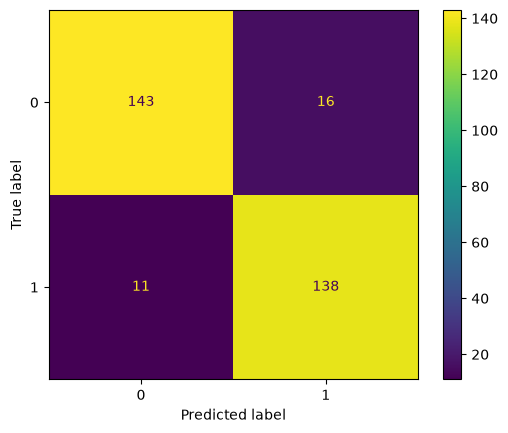

In [12]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from matplotlib import pyplot as plt
# Predictions
y_pred = (model.predict(x_test) > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Precision
print("Precision:", precision_score(y_test, y_pred))

# Recall
print("Recall:", recall_score(y_test, y_pred))

# F1 Score
print("F1 Score:", f1_score(y_test, y_pred))

# Classification Report
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.show()

In [13]:
import numpy as np
new_patient = np.array([[63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 1]])
pred=model.predict(new_patient)
print(pred)
if pred[0][0] > 0.5:
    print("Heart Disease")
else:
    print("No Heart Disease")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
[[7.294246e-33]]
No Heart Disease


In [14]:
model.save("heart_disease_model.keras")

In [15]:
from tensorflow.keras.models import load_model

model = load_model("heart_disease_model.keras")